# Project 02: Gradient Descent Visualizer

## Problem Statement
How does a Machine Learning model find the parameters that minimize its prediction error?

## Objective
Implement Gradient Descent from scratch and visualize how a Linear Regression model learns its slope and intercept.

## Concepts Covered
- Linear Regression
- Mean Squared Error (MSE)
- Cost functions
- Derivatives and gradients
- Learning rate
- Parameter updates
- Convergence

## Tools
Python, NumPy, Matplotlib

## Learning Outcome
By the end of this project, we will see how repeated parameter updates reduce prediction error and help a model find a better-fitting line.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("Gradient Descent Visualizer is ready!")

Gradient Descent Visualizer is ready!


In [2]:
# Study hours (input feature)
X = np.arange(1, 11, dtype=float)

# Create scores with an approximately linear relationship
rng = np.random.default_rng(42)
y = 3 * X + 5 + rng.normal(0, 1, size=len(X))

print("Input data (X):", X)
print("\nTarget values (y):", np.round(y, 2))
print("\nNumber of observations:", len(X))

Input data (X): [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]

Target values (y): [ 8.3   9.96 14.75 17.94 18.05 21.7  26.13 28.68 31.98 34.15]

Number of observations: 10


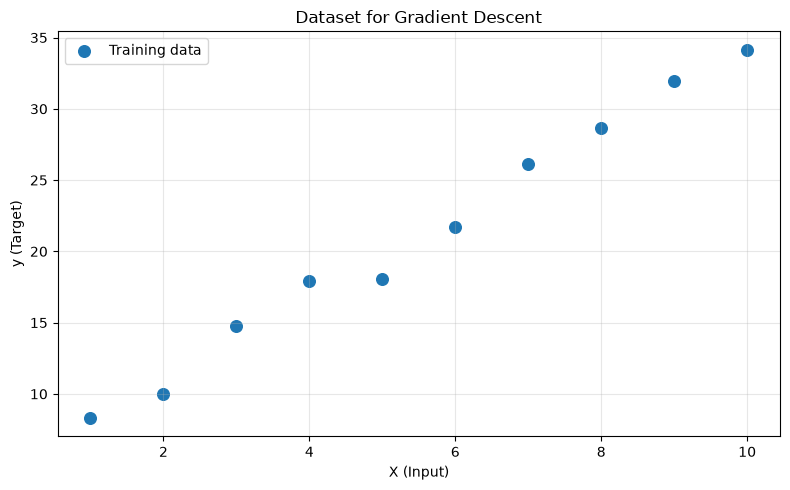

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, s=70, label="Training data")

plt.xlabel("X (Input)")
plt.ylabel("y (Target)")
plt.title("Dataset for Gradient Descent")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [4]:
def predict(X, w, b):
    """Predict output using y_hat = wX + b."""
    return w * X + b


def compute_mse(y_actual, y_predicted):
    """Calculate Mean Squared Error."""
    return np.mean((y_actual - y_predicted) ** 2)


print("Prediction and cost functions defined!")

Prediction and cost functions defined!


In [5]:
# Initialize the model with poor parameters
w = 0.0
b = 0.0

# Generate initial predictions
initial_predictions = w * X + b

# Calculate initial error
initial_mse = np.mean((y - initial_predictions) ** 2)

print("Initial slope:", w)
print("Initial intercept:", b)
print(f"Initial MSE: {initial_mse:.2f}")

Initial slope: 0.0
Initial intercept: 0.0
Initial MSE: 519.85


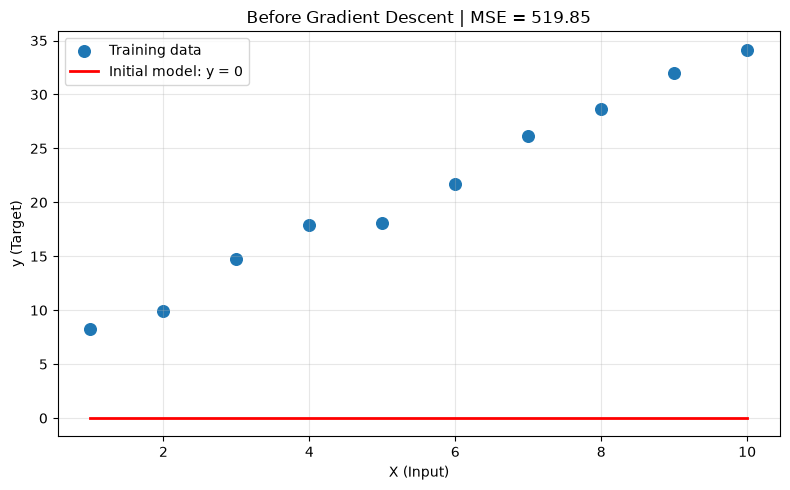

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, s=70, label="Training data")
plt.plot(X, initial_predictions, color="red", linewidth=2,
         label="Initial model: y = 0")

plt.xlabel("X (Input)")
plt.ylabel("y (Target)")
plt.title(f"Before Gradient Descent | MSE = {initial_mse:.2f}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Initialize parameters
w = 0.0
b = 0.0

# Hyperparameters
learning_rate = 0.01
epochs = 1000

# Store the error at each step
loss_history = []

n = len(X)

for epoch in range(epochs):

    # 1. Make predictions
    y_pred = w * X + b

    # 2. Calculate gradients
    dw = (2 / n) * np.sum((y_pred - y) * X)
    db = (2 / n) * np.sum(y_pred - y)

    # 3. Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

    # 4. Calculate and store the new error
    new_predictions = w * X + b
    mse = np.mean((y - new_predictions) ** 2)
    loss_history.append(mse)

print("Training completed!")
print(f"Learned slope: {w:.4f}")
print(f"Learned intercept: {b:.4f}")
print(f"Initial MSE: {initial_mse:.4f}")
print(f"Final MSE: {loss_history[-1]:.4f}")

Training completed!
Learned slope: 2.9467
Learned intercept: 4.9436
Initial MSE: 519.8532
Final MSE: 0.7526


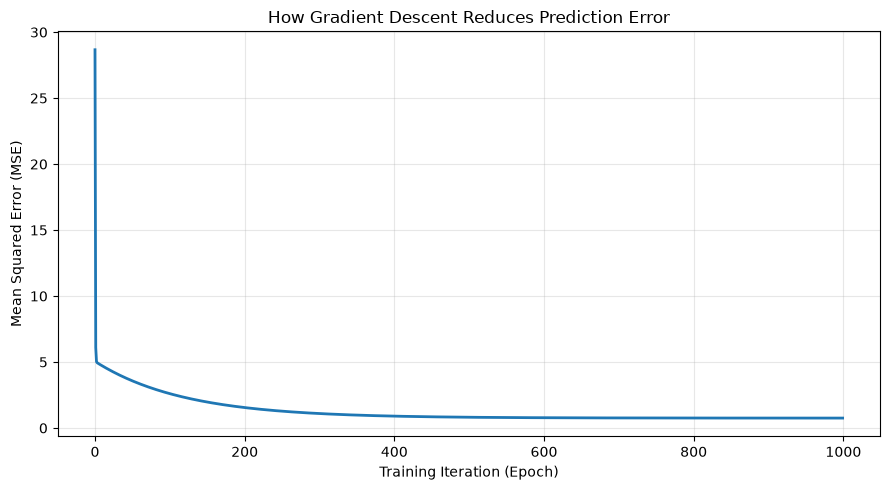

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history, linewidth=2)

plt.xlabel("Training Iteration (Epoch)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("How Gradient Descent Reduces Prediction Error")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("gradient_descent_loss.png", dpi=300, bbox_inches="tight")
plt.show()

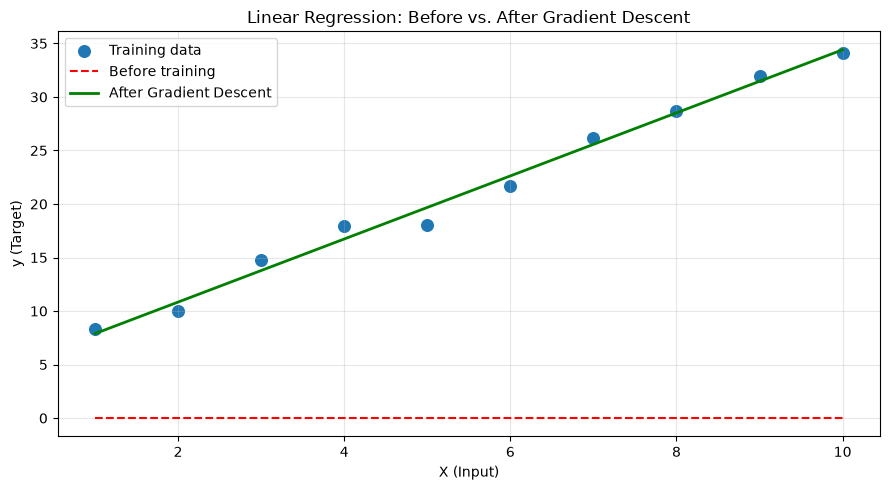

Initial MSE: 519.8532
Final MSE:   0.7526


In [9]:
# Predictions from the trained model
final_predictions = w * X + b

plt.figure(figsize=(9, 5))

plt.scatter(X, y, s=70, label="Training data")

plt.plot(
    X,
    initial_predictions,
    color="red",
    linestyle="--",
    label="Before training"
)

plt.plot(
    X,
    final_predictions,
    color="green",
    linewidth=2,
    label="After Gradient Descent"
)

plt.xlabel("X (Input)")
plt.ylabel("y (Target)")
plt.title("Linear Regression: Before vs. After Gradient Descent")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("gradient_descent_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Initial MSE: {initial_mse:.4f}")
print(f"Final MSE:   {loss_history[-1]:.4f}")

In [10]:
def train_with_learning_rate(lr, epochs=100):
    w = 0.0
    b = 0.0
    losses = []
    n = len(X)

    for _ in range(epochs):
        # Predictions
        y_pred = w * X + b

        # Gradients
        dw = (2 / n) * np.sum((y_pred - y) * X)
        db = (2 / n) * np.sum(y_pred - y)

        # Update parameters
        w -= lr * dw
        b -= lr * db

        # Record loss
        predictions = w * X + b
        mse = np.mean((y - predictions) ** 2)
        losses.append(mse)

    return w, b, losses


learning_rates = [0.001, 0.01, 0.03]
experiments = {}

for lr in learning_rates:
    w_lr, b_lr, losses = train_with_learning_rate(lr)
    experiments[lr] = losses

    print(
        f"Learning rate: {lr:.3f} | "
        f"Final MSE: {losses[-1]:.4f}"
    )

Learning rate: 0.001 | Final MSE: 4.7343
Learning rate: 0.010 | Final MSE: 2.6185
Learning rate: 0.030 | Final MSE: 179172172312180313155377823744.0000


In [11]:
# Calculate error reduction
final_mse = loss_history[-1]
error_reduction = ((initial_mse - final_mse) / initial_mse) * 100

print("=" * 45)
print("GRADIENT DESCENT VISUALIZER — RESULTS")
print("=" * 45)

print(f"Number of observations: {len(X)}")
print(f"Training iterations: {len(loss_history)}")
print(f"Learned slope (w): {w:.4f}")
print(f"Learned intercept (b): {b:.4f}")

print(f"\nInitial MSE: {initial_mse:.4f}")
print(f"Final MSE:   {final_mse:.4f}")
print(f"Error reduction: {error_reduction:.2f}%")

print("\nGenerated visualizations:")
print("- gradient_descent_loss.png")
print("- gradient_descent_comparison.png")
print("- learning_rate_comparison.png")

GRADIENT DESCENT VISUALIZER — RESULTS
Number of observations: 10
Training iterations: 1000
Learned slope (w): 2.9467
Learned intercept (b): 4.9436

Initial MSE: 519.8532
Final MSE:   0.7526
Error reduction: 99.86%

Generated visualizations:
- gradient_descent_loss.png
- gradient_descent_comparison.png
- learning_rate_comparison.png


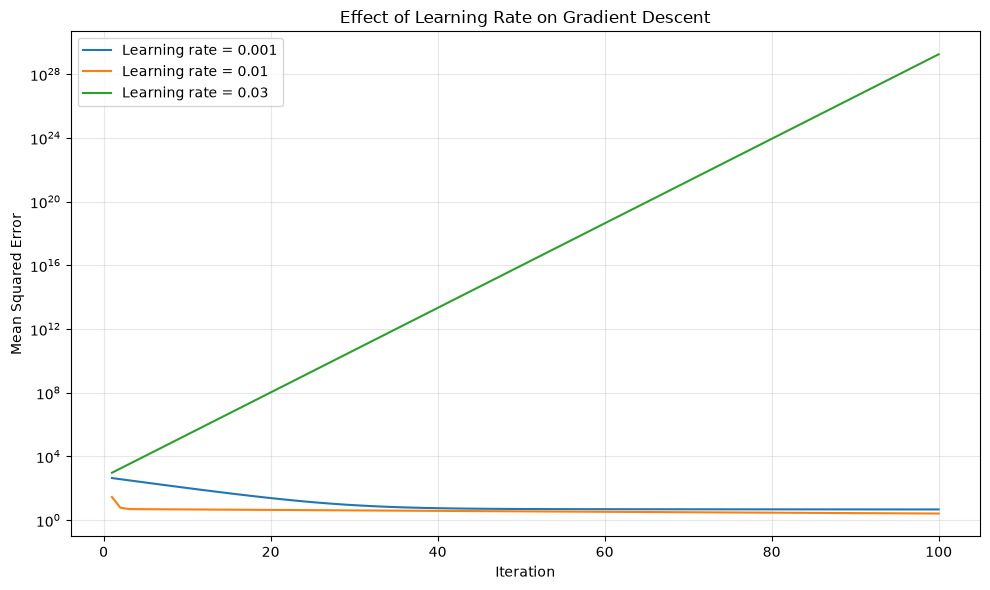

Graph saved successfully at:
/Users/sammy/ai-ml-4-day-build-sprint/day-1-ml-fundamentals/learning_rate_comparison.png


In [12]:
from pathlib import Path
import matplotlib.pyplot as plt

# Find the Day 1 project folder
cwd = Path.cwd()

if cwd.name == "day-1-ml-fundamentals":
    output_dir = cwd
elif (cwd / "day-1-ml-fundamentals").is_dir():
    output_dir = cwd / "day-1-ml-fundamentals"
else:
    output_dir = cwd

# Plot the learning-rate comparison
plt.figure(figsize=(10, 6))

for lr, losses in experiments.items():
    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the graph to the project folder
file_path = output_dir / "learning_rate_comparison.png"

plt.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved successfully at:")
print(file_path.resolve())